What are the dimensions (number of rows and columns) of the dataset?

In [ ]:
import sqlite3 as sq
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import numpy as np
import seaborn as sns
from scipy import stats
import warnings
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving cc_data.csv to cc_data.csv


In [ ]:
cs = pd.read_csv('cc_data.csv')

In [ ]:
print(cs.shape)

(389002, 23)


In [ ]:
cs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 389002 entries, 0 to 389001
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   index                  389002 non-null  int64  
 1   trans_date_trans_time  389002 non-null  object 
 2   cc_num                 389002 non-null  int64  
 3   merchant               389002 non-null  object 
 4   category               389002 non-null  object 
 5   amt                    389002 non-null  float64
 6   first                  389002 non-null  object 
 7   last                   389002 non-null  object 
 8   gender                 389002 non-null  object 
 9   street                 389002 non-null  object 
 10  city                   389002 non-null  object 
 11  state                  389002 non-null  object 
 12  zip                    389002 non-null  int64  
 13  lat                    389002 non-null  float64
 14  long                   389002 non-nu

In [ ]:
cs.head()

,index,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,151888,2019-03-23,3586008444788260,"fraud_Ferry, Lynch and Kautzer",misc_net,1.24,Crystal,Fuller,F,000 Jennifer Mills,...,47.4974,-122.0107,50489,Osteopath,1984-02-29,ff66e2310bf7a2a05e65d6b0a363aa5b,1332471978,47.352172,-121.644080,0
1,1185025,2020-10-05,4671727014157740,fraud_Bogisich Inc,grocery_pos,112.57,Kenneth,Edwards,M,3653 Ryan Crossroad,...,40.8618,-85.6067,2304,Retail banker,1955-07-25,f1edcfa2102065f5f76375c2d20b9081,1368185292,40.265726,-85.914050,0
2,10818,2019-07-01,377993105397617,fraud_Mohr-Bayer,shopping_net,6.69,Nathan,Martinez,M,586 Thomas Cliffs,...,44.8755,-88.1555,5548,Mining engineer,1975-11-09,0caa0ca338d1d2903b92bb42d8905768,1325943086,44.512954,-88.693464,0
3,975275,2020-01-30,4710826438164840000,fraud_Langworth LLC,personal_care,100.69,Juan,Henry,M,9795 Lori Island Suite 346,...,48.8328,-108.3961,192,Further education lecturer,1964-04-01,c7d25a5388311ebd7f2eef77459376ac,1359571786,47.909634,-109.008657,0
4,346814,2019-12-06,372382441451095,fraud_Hills-Witting,shopping_net,7.80,Brent,Terrell,M,502 Rice Plaza Apt. 979,...,41.8948,-73.9767,2471,Heritage manager,1966-01-21,8e1306b47052ac10fe48512de79edf71,1339470288,41.534838,-74.449927,0


In [ ]:
cs.tail()

,index,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
388997,1286992,2020-06-17,30546453310167,fraud_Jakubowski Group,food_dining,55.43,Nicholas,Tran,M,672 Randall Burg Suite 551,...,43.4512,-71.4890,7430,"Scientist, research (medical)",1955-01-13,b7d8dd8e9f941f316e5af3426dce91c0,1371445103,43.573310,-71.975075,0
388998,329380,2019-06-06,3562264947797240,fraud_Lockman Ltd,grocery_pos,111.77,Anthony,Velasquez,M,609 Hunt Grove,...,37.6047,-85.4251,301,"Research officer, political party",1967-03-17,6226318c59455a8a56dadf44307031b6,1338961944,38.538512,-84.999516,0
388999,950878,2020-01-16,4099707841315750,"fraud_Nicolas, Hills and McGlynn",entertainment,52.98,James,Stephens,M,1166 Castillo Mountains,...,38.2586,-78.4074,9815,"Designer, ceramics/pottery",1975-07-07,81287d23caeb5a07d0dd9ff7d61ddd9c,1358342419,38.423962,-78.882504,0
389000,958274,2020-01-20,676118385837,"fraud_Reichert, Huels and Hoppe",shopping_net,3.38,Katelyn,Wise,F,674 Maureen Summit Apt. 276,...,44.9897,-122.6187,1252,"Engineer, petroleum",1937-06-02,b78283119c244578ee42b7f0f7708496,1358671894,45.180731,-122.515971,0
389001,843707,2019-12-14,30135235368675,fraud_Barrows PLC,shopping_pos,139.17,Amanda,Williams,F,02018 Gary Key Apt. 911,...,39.1412,-94.3515,123373,"Engineer, production",1992-11-27,326bf5da22f1a5ddd2a0be58d1684fac,1355487879,39.476791,-94.555094,0


How many unique values are there in each categorical variable?

In [ ]:
unique_counts = cs.select_dtypes(include=['object', 'category']).nunique()

print(unique_counts)

trans_date_trans_time       537
merchant                    693
category                     14
first                       352
last                        481
gender                        2
street                      979
city                        890
state                        51
job                         492
dob                         960
trans_num                389002
dtype: int64


What is the distribution of numerical variables in the dataset?

In [ ]:
def normal_dist(x, mean, sd):
    prob_density = (np.pi*sd) * np.exp(-0.5*((x-mean)/sd)**2)
    return prob_density

mean = 0
sd = 1
x = 1
result = normal_dist(x, mean, sd)
print(result)

1.9054722647301798


/tmp/ipykernel_1373/1193905015.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Month', y='amt', data=cs, palette='Set2', order=['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'])


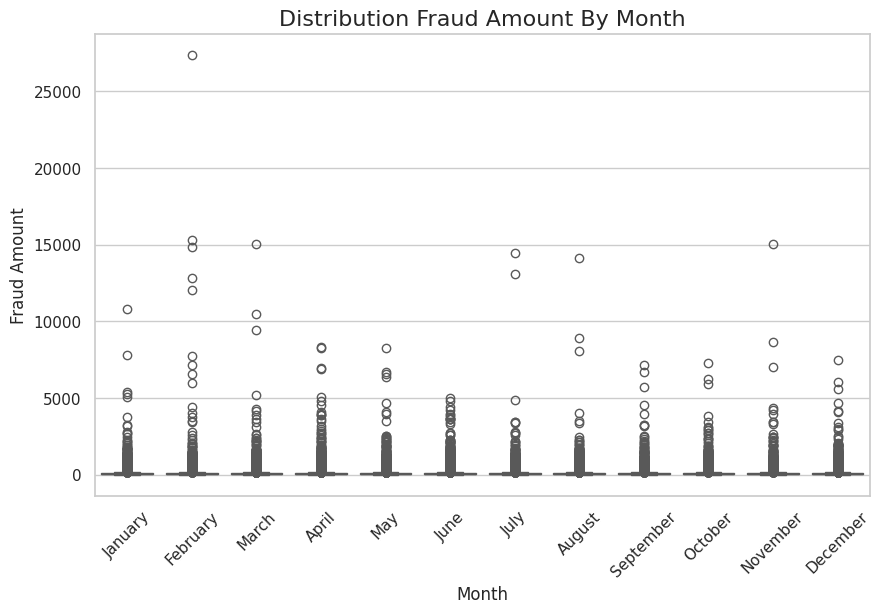

In [ ]:
cs['date_time_obj'] = pd.to_datetime(cs['trans_date_trans_time'], format='%Y-%m-%d')

cs['Date'] = cs['date_time_obj'].dt.date
cs['Time'] = cs['date_time_obj'].dt.time
cs['Month'] = cs['date_time_obj'].dt.month_name()

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.boxplot(x='Month', y='amt', data=cs, palette='Set2', order=['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'])
plt.xticks(rotation=45)

plt.title('Distribution Fraud Amount By Month', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Fraud Amount', fontsize=12)

plt.show()

/tmp/ipykernel_1373/2158067583.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values_metrics, palette='viridis', ax=ax4)


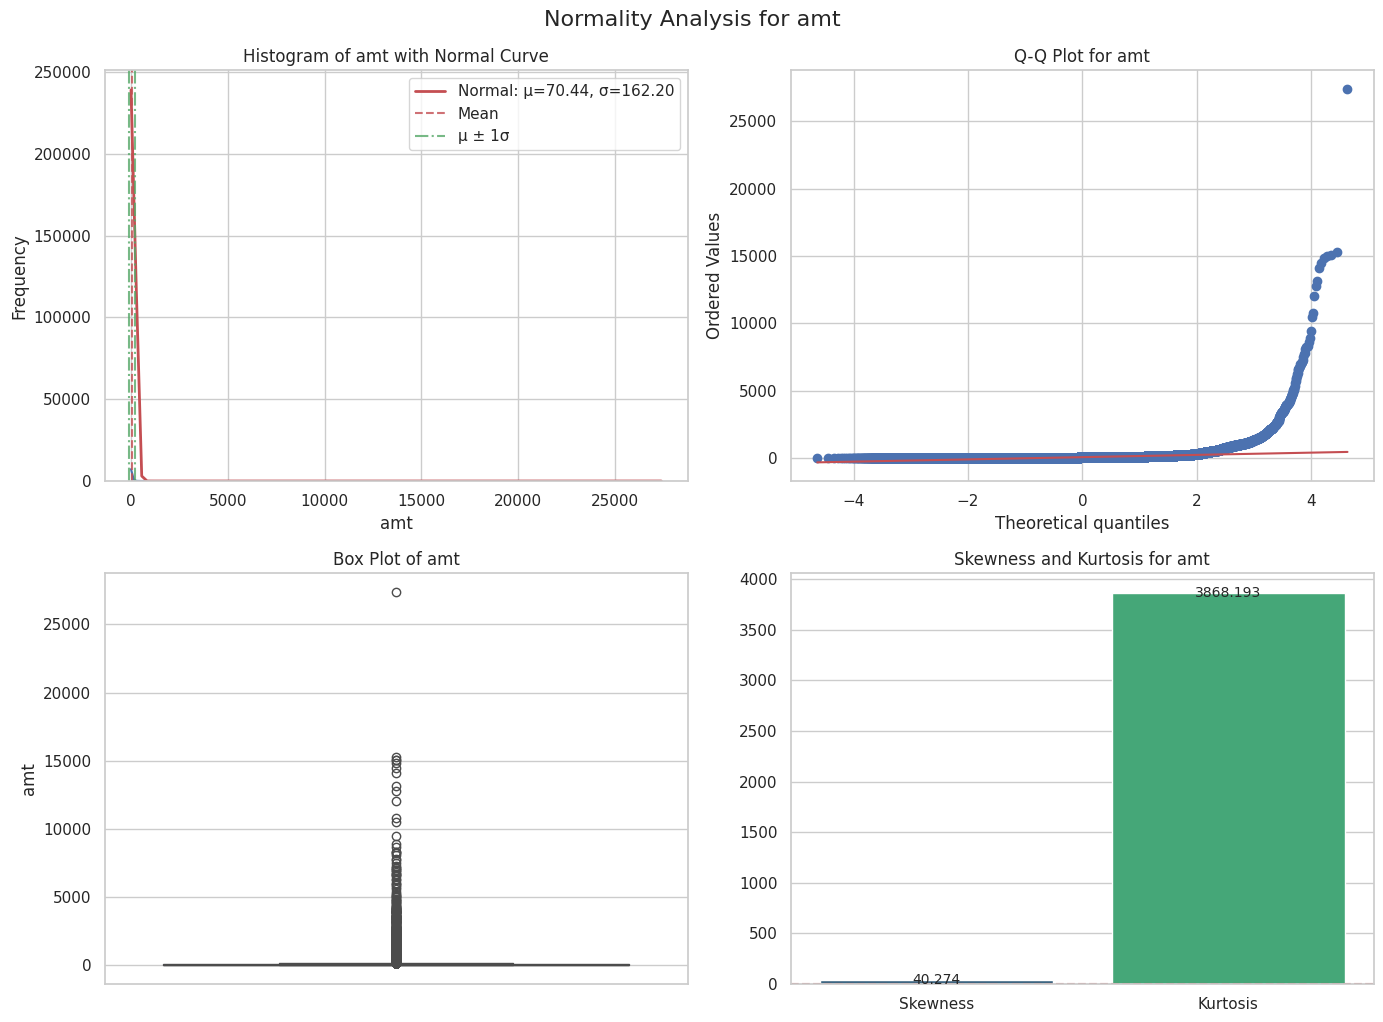


Normality Tests for amt:
Shapiro-Wilk Test: statistic=0.2651, p-value=0.000000
Interpretation (p << 0.05): Reject H0: Data is NOT normally distributed
Note that.. H₀: The data follows a normal distribution
 
Anderson-Darling Test: statistic=62493.3750
Critical values at significance levels:
  15%: 0.5760 - Reject H0: Data is NOT normally distributed
  10%: 0.6560 - Reject H0: Data is NOT normally distributed
  5%: 0.7870 - Reject H0: Data is NOT normally distributed
  2.5%: 0.9180 - Reject H0: Data is NOT normally distributed
  1%: 1.0920 - Reject H0: Data is NOT normally distributed
 

Skewness: 40.2737
  The distribution is positively skewed (right-tailed)
Skewness = 0: Perfectly symmetric distribution 
 Skewness > 0: Right-skewed (positive skew) - the right tail is longer 
 Skewness < 0: Left-skewed (negative skew) - the left tail is longer
 
Kurtosis: 3868.1931
  The distribution has heavier tails than normal (leptokurtic)
Kurtosis = 0: Same tailedness as a normal distribution (me

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 389002.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_1373/2158067583.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values_metrics, palette='viridis', ax=ax4)


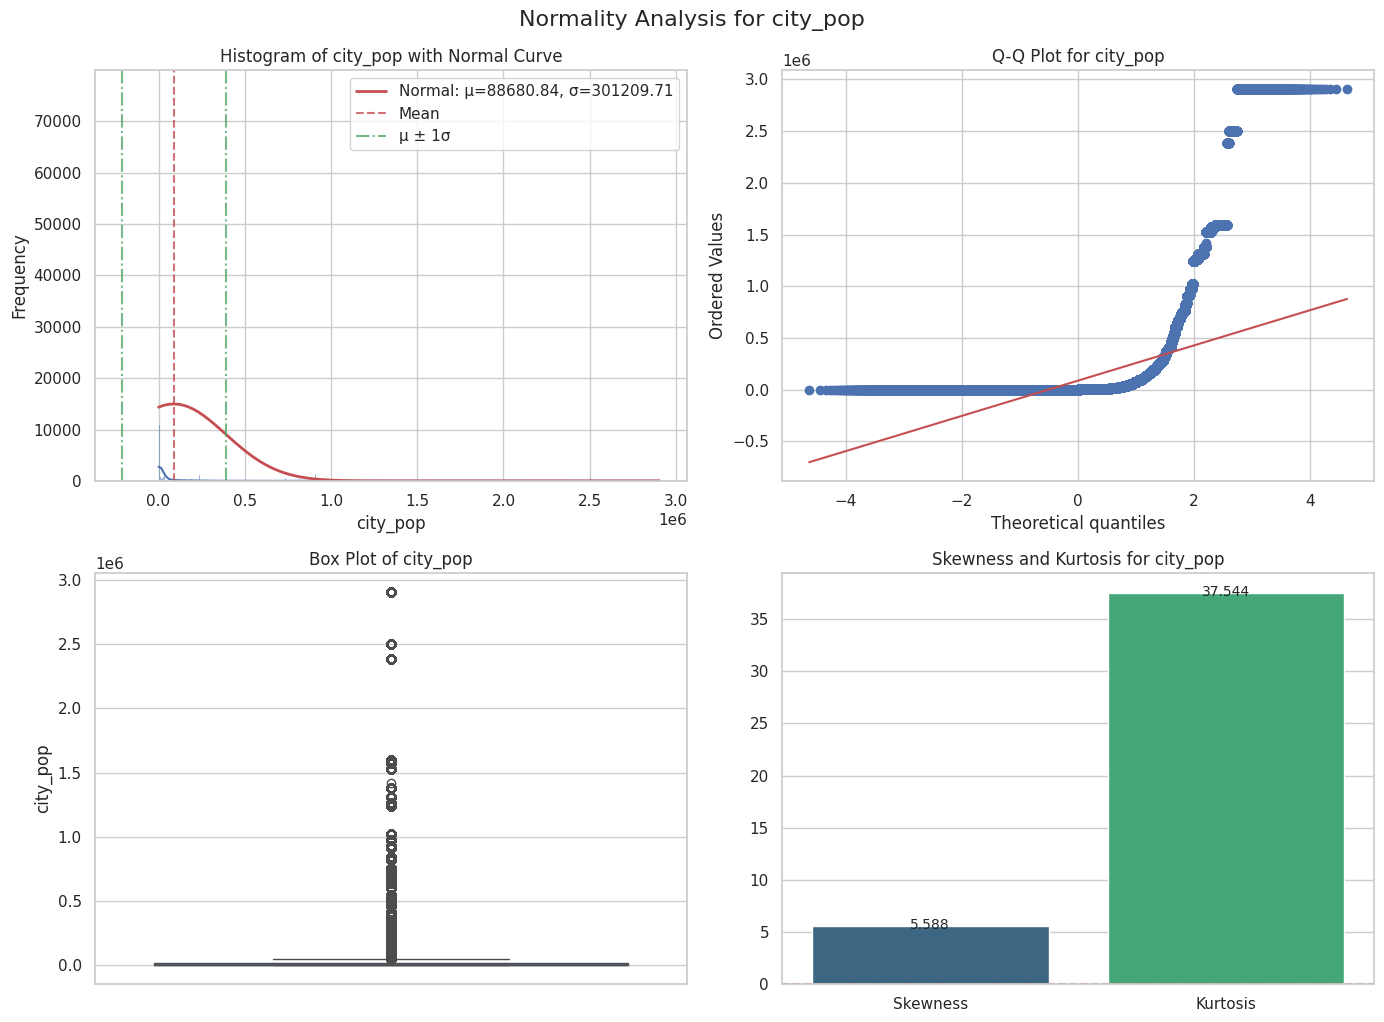


Normality Tests for city_pop:
Shapiro-Wilk Test: statistic=0.3194, p-value=0.000000
Interpretation (p << 0.05): Reject H0: Data is NOT normally distributed
Note that.. H₀: The data follows a normal distribution
 
Anderson-Darling Test: statistic=99928.9382
Critical values at significance levels:
  15%: 0.5760 - Reject H0: Data is NOT normally distributed
  10%: 0.6560 - Reject H0: Data is NOT normally distributed
  5%: 0.7870 - Reject H0: Data is NOT normally distributed
  2.5%: 0.9180 - Reject H0: Data is NOT normally distributed
  1%: 1.0920 - Reject H0: Data is NOT normally distributed
 

Skewness: 5.5879
  The distribution is positively skewed (right-tailed)
Skewness = 0: Perfectly symmetric distribution 
 Skewness > 0: Right-skewed (positive skew) - the right tail is longer 
 Skewness < 0: Left-skewed (negative skew) - the left tail is longer
 
Kurtosis: 37.5438
  The distribution has heavier tails than normal (leptokurtic)
Kurtosis = 0: Same tailedness as a normal distribution (

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 389002.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_1373/2158067583.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values_metrics, palette='viridis', ax=ax4)


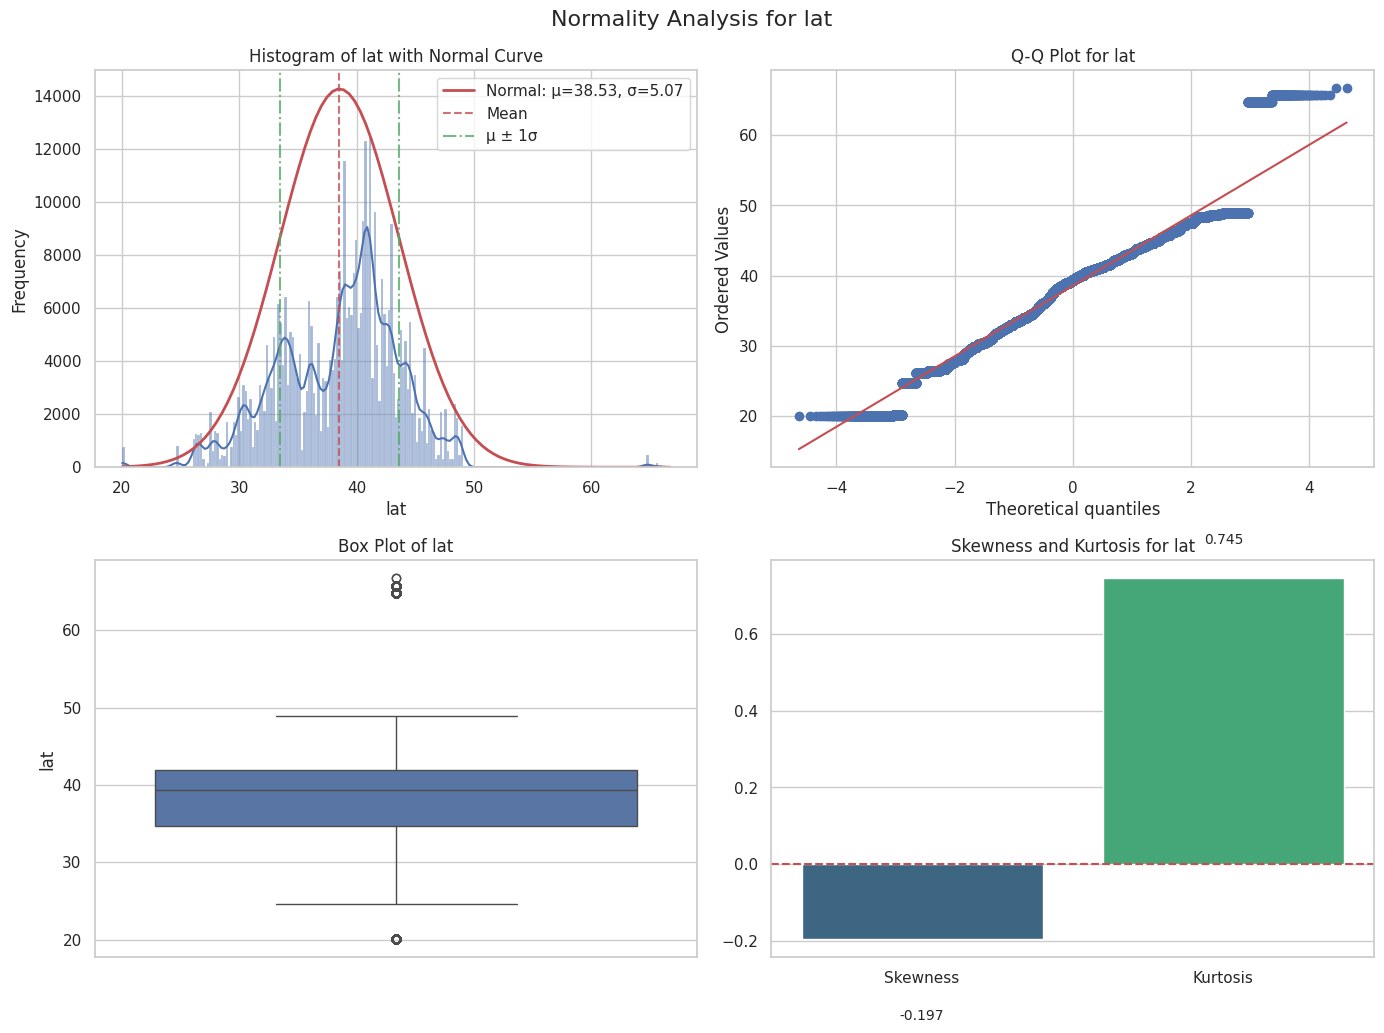


Normality Tests for lat:
Shapiro-Wilk Test: statistic=0.9779, p-value=0.000000
Interpretation (p << 0.05): Reject H0: Data is NOT normally distributed
Note that.. H₀: The data follows a normal distribution
 
Anderson-Darling Test: statistic=2446.2507
Critical values at significance levels:
  15%: 0.5760 - Reject H0: Data is NOT normally distributed
  10%: 0.6560 - Reject H0: Data is NOT normally distributed
  5%: 0.7870 - Reject H0: Data is NOT normally distributed
  2.5%: 0.9180 - Reject H0: Data is NOT normally distributed
  1%: 1.0920 - Reject H0: Data is NOT normally distributed
 

Skewness: -0.1969
  The distribution is approximately symmetric
Skewness = 0: Perfectly symmetric distribution 
 Skewness > 0: Right-skewed (positive skew) - the right tail is longer 
 Skewness < 0: Left-skewed (negative skew) - the left tail is longer
 
Kurtosis: 0.7454
  The distribution has heavier tails than normal (leptokurtic)
Kurtosis = 0: Same tailedness as a normal distribution (mesokurtic) 
 K

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 389002.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_1373/2158067583.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values_metrics, palette='viridis', ax=ax4)


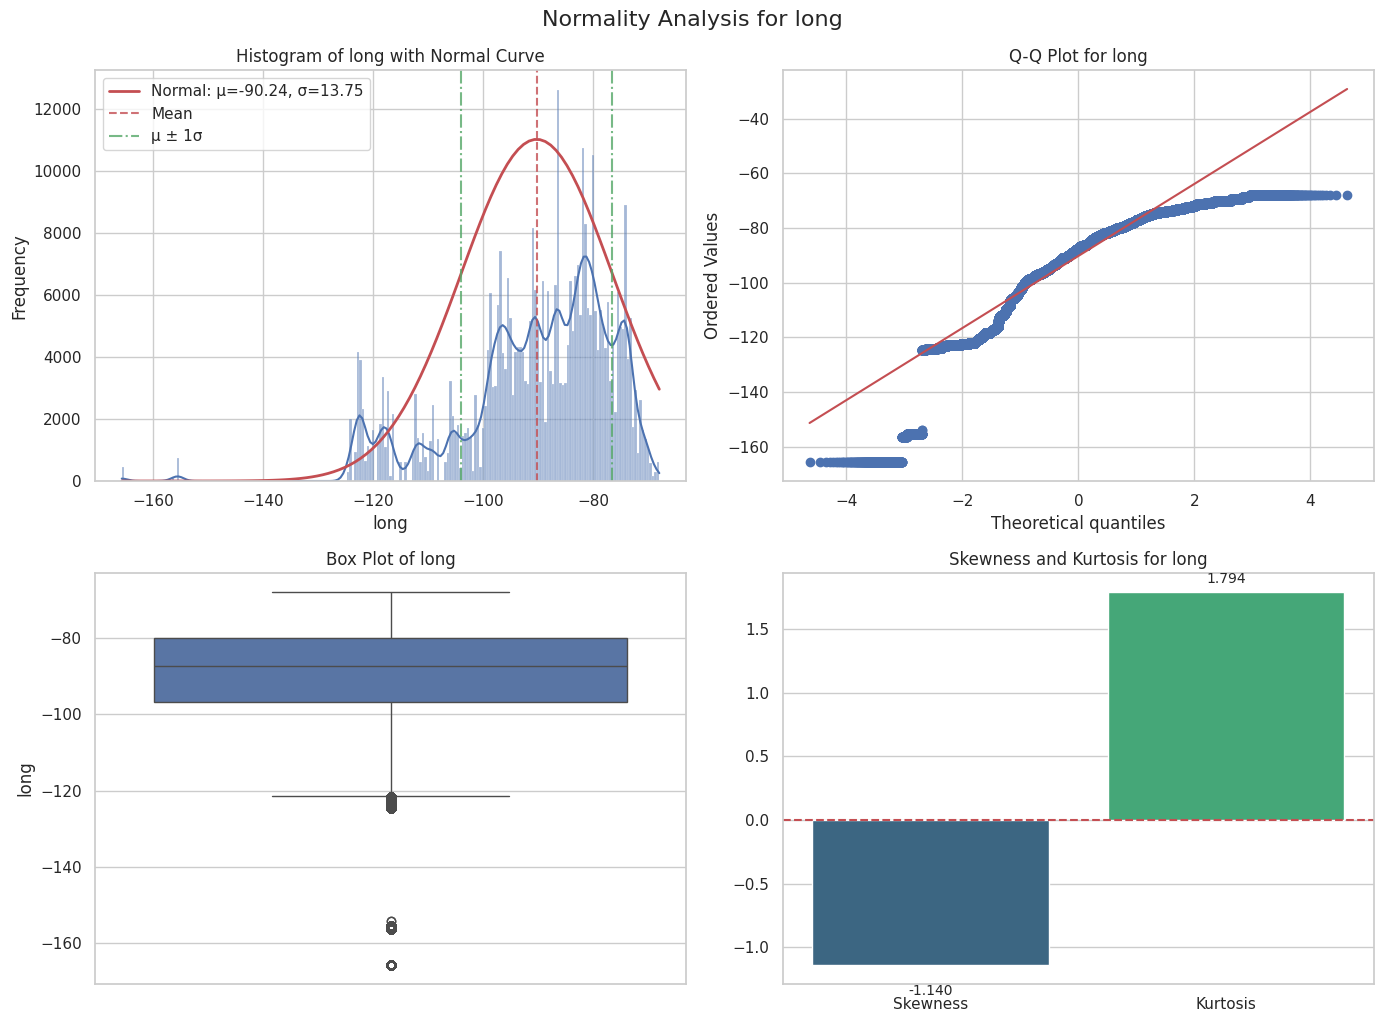


Normality Tests for long:
Shapiro-Wilk Test: statistic=0.9178, p-value=0.000000
Interpretation (p << 0.05): Reject H0: Data is NOT normally distributed
Note that.. H₀: The data follows a normal distribution
 
Anderson-Darling Test: statistic=7793.0109
Critical values at significance levels:
  15%: 0.5760 - Reject H0: Data is NOT normally distributed
  10%: 0.6560 - Reject H0: Data is NOT normally distributed
  5%: 0.7870 - Reject H0: Data is NOT normally distributed
  2.5%: 0.9180 - Reject H0: Data is NOT normally distributed
  1%: 1.0920 - Reject H0: Data is NOT normally distributed
 

Skewness: -1.1404
  The distribution is negatively skewed (left-tailed)
Skewness = 0: Perfectly symmetric distribution 
 Skewness > 0: Right-skewed (positive skew) - the right tail is longer 
 Skewness < 0: Left-skewed (negative skew) - the left tail is longer
 
Kurtosis: 1.7936
  The distribution has heavier tails than normal (leptokurtic)
Kurtosis = 0: Same tailedness as a normal distribution (mesoku

/usr/local/lib/python3.12/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 389002.
  res = hypotest_fun_out(*samples, **kwds)


In [ ]:
columns_to_analyze = ['amt', 'city_pop', 'lat', 'long']

def check_normality(data, column):
    values = data[column]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    plt.subplots_adjust(hspace=0.4, wspace=0.4)

    ax1 = axes[0, 0]
    sns.histplot(values, kde=True, ax=ax1)

    mu, std = stats.norm.fit(values)
    x = np.linspace(min(values), max(values), 100)
    p = stats.norm.pdf(x, mu, std)
    ax1.plot(x, p * len(values) * (max(values) - min(values)) / 100,
            'r-', linewidth=2, label=f'Normal: μ={mu:.2f}, σ={std:.2f}')

    ax1.axvline(mu, color='r', linestyle='--', alpha=0.8, label='Mean')
    ax1.axvline(mu + std, color='g', linestyle='-.', alpha=0.8, label='μ ± 1σ')
    ax1.axvline(mu - std, color='g', linestyle='-.', alpha=0.8)

    ax1.set_title(f'Histogram of {column} with Normal Curve')
    ax1.set_xlabel(column)
    ax1.set_ylabel('Frequency')
    ax1.legend()

    ax2 = axes[0, 1]
    stats.probplot(values, dist="norm", plot=ax2)
    ax2.set_title(f'Q-Q Plot for {column}')

    ax3 = axes[1, 0]
    sns.boxplot(y=values, ax=ax3)
    ax3.set_title(f'Box Plot of {column}')
    ax3.set_ylabel(column)

    ax4 = axes[1, 1]

    skewness = stats.skew(values)
    kurtosis = stats.kurtosis(values)

    metrics = ['Skewness', 'Kurtosis']
    values_metrics = [skewness, kurtosis]

    sns.barplot(x=metrics, y=values_metrics, palette='viridis', ax=ax4)
    ax4.axhline(y=0, color='r', linestyle='--')
    ax4.set_title(f'Skewness and Kurtosis for {column}')

    for i, v in enumerate(values_metrics):
        ax4.text(i, v + 0.1 if v >= 0 else v - 0.2, f'{v:.3f}',
                ha='center', va='center', fontsize=10)

    plt.tight_layout()
    plt.suptitle(f'Normality Analysis for {column}', fontsize=16, y=1.02)
    plt.show()

    print(f"\nNormality Tests for {column}:")

    stat_shapiro, p_shapiro = stats.shapiro(values)
    print(f"Shapiro-Wilk Test: statistic={stat_shapiro:.4f}, p-value={p_shapiro:.6f}")
    if p_shapiro < 0.05:
        result_shapiro = "Reject H0: Data is NOT normally distributed"
    else:
        result_shapiro = "Fail to reject H0: Data looks normally distributed"
    print(f"Interpretation (p << 0.05): {result_shapiro}")
    print("Note that.. H₀: The data follows a normal distribution")
    print(" ")

    result_ad = stats.anderson(values, dist='norm')
    print(f"Anderson-Darling Test: statistic={result_ad.statistic:.4f}")
    print("Critical values at significance levels:")
    for i, significance in enumerate(result_ad.critical_values):
        sig_level = [15, 10, 5, 2.5, 1][i]
        if result_ad.statistic > significance:
            result_ad_i = "Reject H0: Data is NOT normally distributed"
        else:
            result_ad_i = "Fail to reject H0: Data looks normally distributed"
        print(f"  {sig_level}%: {significance:.4f} - {result_ad_i}")

    print(" ")


    print(f"\nSkewness: {skewness:.4f}")
    if abs(skewness) < 0.5:
        print("  The distribution is approximately symmetric")
    elif skewness < -0.5:
        print("  The distribution is negatively skewed (left-tailed)")
    else:
        print("  The distribution is positively skewed (right-tailed)")
    print("Skewness = 0: Perfectly symmetric distribution \n Skewness > 0: Right-skewed (positive skew) - the right tail is longer \n Skewness < 0: Left-skewed (negative skew) - the left tail is longer")

    print (" ")

    print(f"Kurtosis: {kurtosis:.4f}")
    if abs(kurtosis) < 0.5:
        print("  The distribution has kurtosis similar to normal distribution (mesokurtic)")
    elif kurtosis < -0.5:
        print("  The distribution has lighter tails than normal (platykurtic)")
    else:
        print("  The distribution has heavier tails than normal (leptokurtic)")
    print("Kurtosis = 0: Same tailedness as a normal distribution (mesokurtic) \n Kurtosis > 0: Heavier tails than normal (leptokurtic) - more outliers \n Kurtosis < 0: Lighter tails than normal (platykurtic) - fewer outliers")


for column in columns_to_analyze:
    check_normality(cs, column)

In [ ]:
fig = px.histogram(cs, x="amt", color="category",
                   marginal="rug", title="Distribution of Amount By Category")

fig.show()

Are there any missing values in the dataset? If so, how should they be handled?

In [ ]:
print("\nMissing values per column:")
print(cs.isnull().sum())


Missing values per column:
index                    0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
date_time_obj            0
Date                     0
Time                     0
Month                    0
dtype: int64


There are no missing values in the data set.

What are the summary statistics (mean, median, min, max, etc.) for numerical variables?

In [ ]:
cs.describe()

,index,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud,date_time_obj
count,3.890020e+05,3.890020e+05,389002.000000,389002.000000,389002.000000,389002.000000,3.890020e+05,3.890020e+05,389002.000000,389002.000000,389002.000000,389002
mean,6.485205e+05,4.191512e+17,70.442148,48818.064295,38.533121,-90.237664,8.868084e+04,1.349251e+09,38.531683,-90.236674,0.005789,2019-10-07 05:56:36.439092736
min,1.100000e+01,6.041621e+10,1.000000,1257.000000,20.027100,-165.672300,2.300000e+01,1.325376e+09,19.029798,-166.669638,0.000000,2019-01-01 00:00:00
25%,3.241842e+05,1.800429e+14,9.660000,26237.000000,34.620500,-96.798000,7.430000e+02,1.338751e+09,34.719394,-96.905445,0.000000,2019-05-25 00:00:00
50%,6.486485e+05,3.521417e+15,47.570000,48174.000000,39.354300,-87.476900,2.456000e+03,1.349267e+09,39.361065,-87.446843,0.000000,2019-09-23 00:00:00
75%,9.735032e+05,4.642255e+15,83.077500,72011.000000,41.940400,-80.158000,2.032800e+04,1.359460e+09,41.956012,-80.253831,0.000000,2020-02-02 00:00:00
max,1.296674e+06,4.992346e+18,27390.120000,99783.000000,66.693300,-67.950300,2.906700e+06,1.371817e+09,67.064277,-66.956540,1.000000,2020-12-06 00:00:00
std,3.745744e+05,1.311579e+18,162.203915,26879.383224,5.074596,13.745855,3.012101e+05,1.285085e+07,5.109400,13.757311,0.075866,NaN


In [ ]:
print(cs.describe())

              index        cc_num            amt            zip  \
count  3.890020e+05  3.890020e+05  389002.000000  389002.000000   
mean   6.485205e+05  4.191512e+17      70.442148   48818.064295   
min    1.100000e+01  6.041621e+10       1.000000    1257.000000   
25%    3.241842e+05  1.800429e+14       9.660000   26237.000000   
50%    6.486485e+05  3.521417e+15      47.570000   48174.000000   
75%    9.735032e+05  4.642255e+15      83.077500   72011.000000   
max    1.296674e+06  4.992346e+18   27390.120000   99783.000000   
std    3.745744e+05  1.311579e+18     162.203915   26879.383224   

                 lat           long      city_pop     unix_time  \
count  389002.000000  389002.000000  3.890020e+05  3.890020e+05   
mean       38.533121     -90.237664  8.868084e+04  1.349251e+09   
min        20.027100    -165.672300  2.300000e+01  1.325376e+09   
25%        34.620500     -96.798000  7.430000e+02  1.338751e+09   
50%        39.354300     -87.476900  2.456000e+03  1.349267e+

Is there any correlation between numerical variables? If so, how strong is the correlation?

In [ ]:
correlation_columns = ['amt', 'city_pop', 'lat', 'long']

correlation_data = cs[correlation_columns]

correlation_matrix_amount = cs[correlation_columns].corr()

In [ ]:
correlation_matrix_amount

,amt,city_pop,lat,long
amt,1.000000,0.007271,-0.000445,-0.000517
city_pop,0.007271,1.000000,-0.155972,-0.053461
lat,-0.000445,-0.155972,1.000000,-0.016080
long,-0.000517,-0.053461,-0.016080,1.000000


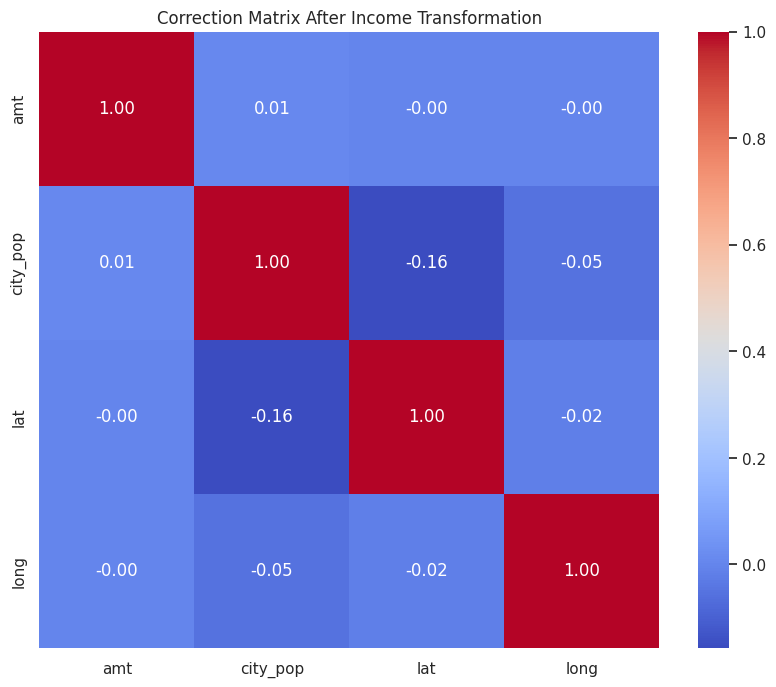

In [ ]:
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix_amount, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correction Matrix After Income Transformation')
plt.show()

How does the distribution of an amt differ across is_fraud categories?

In [19]:
cs.groupby('is_fraud')['amt'].describe()

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,386750.0,67.834157,156.227752,1.00,9.6200,47.330,82.5000,27390.12
1,2252.0,518.328677,389.127281,1.18,147.8825,365.285,888.3425,1294.83


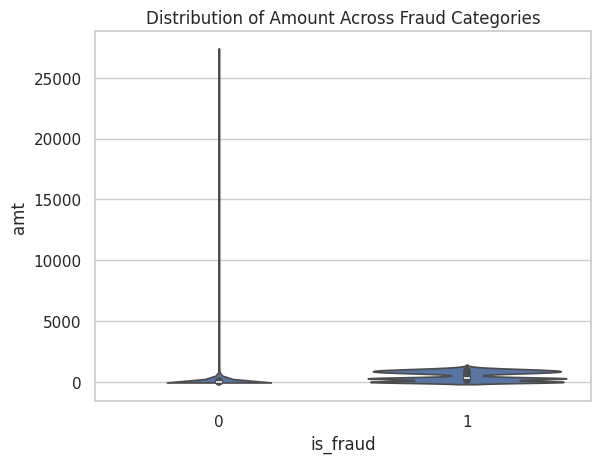

In [20]:
sns.boxplot(x='is_fraud', y='amt', data=cs)
plt.title('Distribution of Amount Across Fraud Categories')
plt.show()

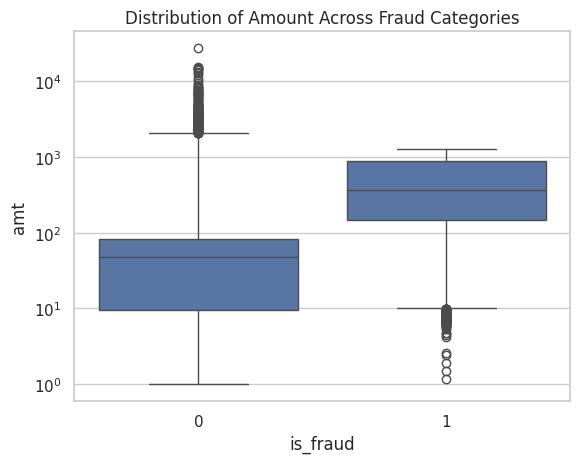

In [23]:
plt.yscale('log')
sns.boxplot(x='is_fraud', y='amt', data=cs)
plt.title('Distribution of Amount Across Fraud Categories')
plt.show()

Are there any outliers in the city_pop and amt?

In [25]:
for col in ['city_pop', 'amt']:
  Q1 = cs[col].quantile(0.25)
  Q3 = cs[col].quantile(0.75)
  IQR = Q3 - Q1
  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  outliers = cs[(cs[col] < lower) | (cs[col] > upper)]

  print(f'Outliers in {col}:')
  print(outliers)

Outliers in city_pop:
          index trans_date_trans_time            cc_num  \
0        151888            2019-03-23  3586008444788260   
9        238768            2019-04-29    30541100351706   
13       296280            2019-05-25     4809701904914   
16       502680            2019-06-08  4952583804639900   
21       215513            2019-04-20  6011148190095200   
...         ...                   ...               ...   
388981   288916            2019-05-22  4635330563105900   
388986   700336            2019-10-26  6011348830550190   
388988   400455            2019-01-07  4997733566924480   
388993  1259245            2020-08-06     4900628639996   
389001   843707            2019-12-14    30135235368675   

                                   merchant       category     amt      first  \
0            fraud_Ferry, Lynch and Kautzer       misc_net    1.24    Crystal   
9       fraud_Hettinger, McCullough and Fay           home   49.14    Derrick   
13                        

Are there any trends or patterns in the data over time (if applicable)?

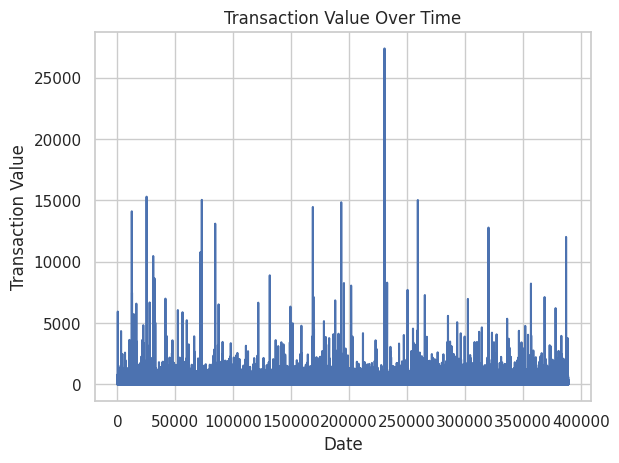

In [28]:
cs['date_time_obj'] = pd.to_datetime(cs['trans_date_trans_time'], format='%Y-%m-%d')

cs['Date'] = cs['date_time_obj'].dt.date

cs['amt'].plot(title='Transaction Value Over Time')
plt.xlabel('Date')
plt.ylabel('Transaction Value')
plt.show()

How does the target variable (if available) distribute across different categories?

In [32]:
print(cs['is_fraud'].value_counts())
print(cs['is_fraud'].value_counts(normalize=True))

is_fraud
0    386750
1      2252
Name: count, dtype: int64
is_fraud
0    0.994211
1    0.005789
Name: proportion, dtype: float64


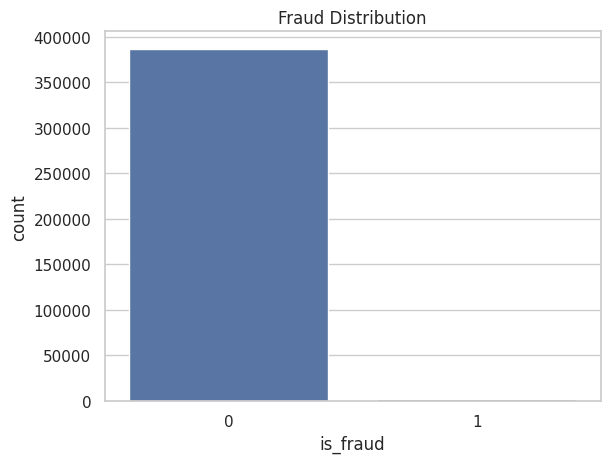

In [33]:
sns.countplot(x='is_fraud', data=cs)
plt.title('Fraud Distribution')
plt.show()

Are there any unusual or unexpected values in the dataset that require further investigation?

- Nothing that comes to mind is unusual or unexpected.

Are there any potential data entry errors or inconsistencies in the dataset?

- No, there are no data errors or inconsistencies in the dataset

- In the CardNumber column, there are duplicates listed in the column. One who is accessing the dataset could potentially misread the column and assume there are duplicates in the data set. But the index column (First column) there are no duplicates. Therefore, there are only multiple occurances of the card numbers.

How does the distribution of numerical variables vary between different groups or segments of the dataset?

fraud by gender and categories

states and number of transactions

transaction amount by job roles

In [43]:
summary = cs.groupby(['category', 'gender', 'is_fraud', 'state', 'merchant', 'job'])[
    'amt'
].agg(['count', 'mean', 'median', 'std'])

print(summary)

                                                                                                  count  \
category      gender is_fraud state merchant                            job                               
entertainment F      0        AL    fraud_Abbott-Rogahn                 Ceramics designer             1   
                                                                        Drilling engineer             1   
                                                                        Materials engineer            3   
                                                                        Presenter, broadcasting       1   
                                                                        Surveyor, land/geomatics      2   
...                                                                                                 ...   
travel        M      1        NY    fraud_Ankunding-Carroll             TEFL teacher                  1   
                                    f

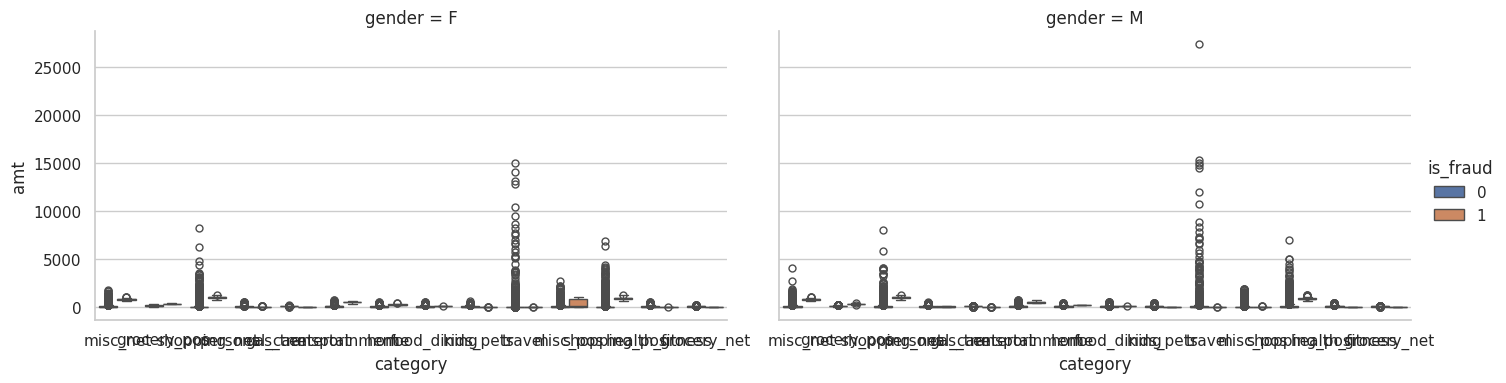

In [42]:
sns.catplot(
    data=cs,
    x='category',
    y='amt',
    hue='is_fraud',
    col='gender',
    kind='box',
    height=4,
    aspect=1.8,
)

plt.show()

What are the **top factors** that influence the target variable, if applicable?

- The top factors that influence the target variable is_fraud are merchant, categories, and the month of the transaction.

Write an **analysis report** on performing exploratory data analysis (EDA) using Python in the context of building a fraud detection system for the financial industry.

## Exploratory Data Analysis (EDA) Report for Fraud Detection

This report summarizes the key findings from the Exploratory Data Analysis (EDA) performed on the financial transaction dataset, aiming to identify patterns and insights relevant to building a fraud detection system.

### 1. Dataset Overview

The dataset `cs` contains **389,002 rows** and **23 columns**. It includes a mix of numerical (e.g., `amt`, `city_pop`, `lat`, `long`, `unix_time`) and categorical/object features (e.g., `merchant`, `category`, `gender`, `state`, `job`). Crucially, the target variable `is_fraud` indicates whether a transaction is fraudulent (1) or legitimate (0).

### 2. Missing Values

An initial check revealed **no missing values** across any of the columns in the dataset. This simplifies preprocessing, as no imputation strategies are immediately required.

### 3. Numerical Variable Analysis

*   **`amt` (Transaction Amount)**:
    *   The `amt` column exhibits a **highly right-skewed and leptokurtic (heavy-tailed) distribution**, indicating a large number of small transactions and a few extremely large transactions. This is typical in financial data, where fraudulent transactions often involve higher amounts.
    *   Shapiro-Wilk and Anderson-Darling tests strongly reject the hypothesis of normality, confirming its non-normal distribution.
    *   Outliers are present, particularly on the higher end, which is expected given the skewness and is highly relevant for fraud detection.

*   **`city_pop`, `lat`, `long`**:
    *   These columns also show **non-normal distributions**, with varying degrees of skewness and kurtosis. For instance, `city_pop` is also right-skewed with significant outliers. This suggests that basic statistical models assuming normality might not be appropriate without prior transformations.

*   **Correlation Matrix**:
    *   The correlation matrix for `amt`, `city_pop`, `lat`, and `long` shows **very weak correlations** between these numerical features. This implies that these variables are largely independent of each other in terms of linear relationships.

### 4. Categorical Variable Analysis

*   **`is_fraud` (Target Variable) Distribution**:
    *   The dataset is **highly imbalanced**, with only **0.5789%** (approximately 2,252 out of 389,002) of transactions identified as fraudulent. This imbalance is a critical challenge for model training and will require specialized handling (e.g., oversampling, undersampling, or using appropriate evaluation metrics).

*   **Distribution of `amt` across `is_fraud` categories**:
    *   Fraudulent transactions (`is_fraud` = 1) tend to have **significantly higher transaction amounts** compared to legitimate transactions (`is_fraud` = 0). This is a strong indicator for fraud detection. The log-scaled box plot clearly illustrates this separation, with the median fraudulent transaction amount being considerably higher.

*   **`category`, `gender`, `state`, `merchant`, `job`**: (Based on `summary` table and `catplot`)
    *   The `groupby` analysis reveals that fraud patterns vary significantly across combinations of `category`, `gender`, `state`, `merchant`, and `job`. For example, certain categories or merchants might have a higher incidence of fraud or different average fraudulent amounts.
    *   The `catplot` of `amt` by `category` and `gender` shows distinct distributions of transaction amounts for fraudulent vs. non-fraudulent transactions within specific categories and genders, suggesting these are important features.

### 5. Time-Series Analysis

*   **Transaction Value Over Time**:
    *   The plot of `amt` over time (using `date_time_obj`) shows fluctuations in transaction values. There are noticeable spikes, indicating periods with exceptionally high transaction amounts. Investigating whether these spikes correlate with fraudulent activity could provide further insights.
*   **Distribution of Fraud Amount By Month**:
    *   The box plot of `amt` by `Month` indicates that the distribution of transaction amounts (and potential fraud) does not show a strong seasonal pattern across months in terms of median values, but some months might exhibit a wider range or more extreme outliers in `amt`.

### 6. Key Findings for Fraud Detection

1.  **Extreme Class Imbalance**: The most significant challenge is the highly skewed distribution of the target variable (`is_fraud`).
2.  **Transaction Amount as a Key Indicator**: Fraudulent transactions are strongly associated with higher transaction amounts.
3.  **Categorical Feature Importance**: `category`, `gender`, `state`, `merchant`, and `job` appear to be influential features, with fraud patterns varying considerably across their unique combinations.
4.  **Non-Normal Numerical Data**: `amt` and `city_pop` are not normally distributed and contain outliers, requiring careful handling during feature engineering and model selection.
5.  **Weak Linear Correlations**: Numerical features have weak linear correlations, suggesting that linear models might not capture complex relationships without feature transformations.

### 7. Next Steps

Based on these findings, future steps for building a robust fraud detection system should include:

*   **Data Preprocessing**: Handling skewed distributions (e.g., log transformations, power transforms), managing outliers, and potentially encoding categorical features appropriately.
*   **Feature Engineering**: Creating new features from existing ones (e.g., age from DOB, transaction frequency, ratio features, time-based features like day of week/hour of day).
*   **Addressing Class Imbalance**: Techniques like SMOTE, ADASYN, or using appropriate loss functions for imbalanced datasets.
*   **Model Selection**: Considering models that are robust to skewed data and class imbalance, such as tree-based models (e.g., XGBoost, LightGBM) or neural networks, potentially combined with ensemble methods.
*   **Evaluation Metrics**: Focusing on metrics like Precision, Recall, F1-score, and AUC-ROC, which are more informative than accuracy for imbalanced datasets.